In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Global config
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

DATA_DIR = 'E:\\Uday\\College_Work\\Sem 3\\Mini Project\\MediPredict\\data\\raw'

In [10]:
df = pd.read_csv(f'{DATA_DIR}/dataset.csv')
print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst 3 rows:")
df.head(3)

Shape: (4920, 18)

Columns: ['Disease', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']

First 3 rows:


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Disease     4920 non-null   object
 1   Symptom_1   4920 non-null   object
 2   Symptom_2   4920 non-null   object
 3   Symptom_3   4920 non-null   object
 4   Symptom_4   4572 non-null   object
 5   Symptom_5   3714 non-null   object
 6   Symptom_6   2934 non-null   object
 7   Symptom_7   2268 non-null   object
 8   Symptom_8   1944 non-null   object
 9   Symptom_9   1692 non-null   object
 10  Symptom_10  1512 non-null   object
 11  Symptom_11  1194 non-null   object
 12  Symptom_12  744 non-null    object
 13  Symptom_13  504 non-null    object
 14  Symptom_14  306 non-null    object
 15  Symptom_15  240 non-null    object
 16  Symptom_16  192 non-null    object
 17  Symptom_17  72 non-null     object
dtypes: object(18)
memory usage: 692.0+ KB


Missing values per column:
Symptom_17    4848
Symptom_16    4728
Symptom_15    4680
Symptom_14    4614
Symptom_13    4416
Symptom_12    4176
Symptom_11    3726
Symptom_10    3408
Symptom_9     3228
Symptom_8     2976
Symptom_7     2652
Symptom_6     1986
Symptom_5     1206
Symptom_4      348
Symptom_1        0
Symptom_3        0
Symptom_2        0
Disease          0
dtype: int64


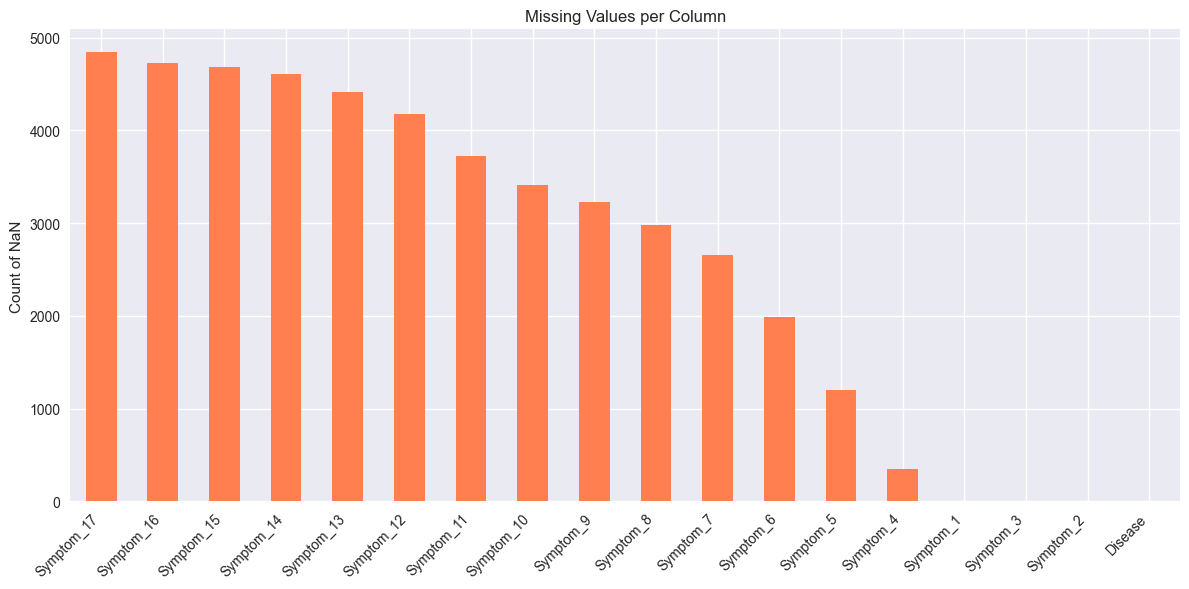

In [12]:
missing = df.isnull().sum().sort_values(ascending=False)
print("Missing values per column:")
print(missing)

# Visualize
plt.figure(figsize=(12, 6))
missing.plot(kind='bar', color='coral')
plt.title('Missing Values per Column')
plt.ylabel('Count of NaN')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../reports/eda_missing_symptoms.png', dpi=150)
plt.show()

Total diseases: 41
Total rows: 4920

Rows per disease (top 10):
Disease
Fungal infection                120
Hepatitis C                     120
Hepatitis E                     120
Alcoholic hepatitis             120
Tuberculosis                    120
Common Cold                     120
Pneumonia                       120
Dimorphic hemmorhoids(piles)    120
Heart attack                    120
Varicose veins                  120
Name: count, dtype: int64


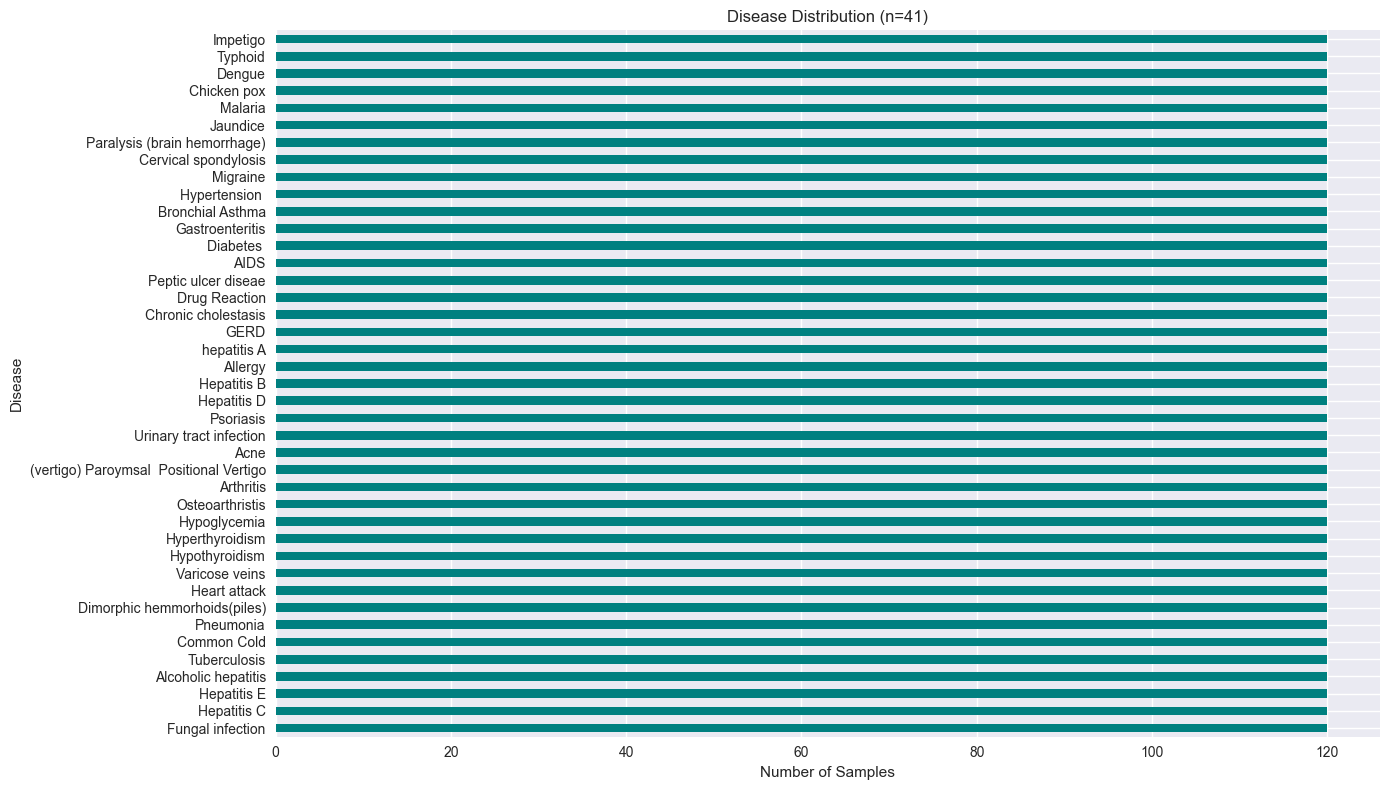

In [13]:
disease_counts = df['Disease'].value_counts()
print(f"Total diseases: {df['Disease'].nunique()}")
print(f"Total rows: {len(df)}")
print(f"\nRows per disease (top 10):")
print(disease_counts.head(10))

# Plot distribution
plt.figure(figsize=(14, 8))
disease_counts.plot(kind='barh', color='teal')
plt.title(f'Disease Distribution (n={df["Disease"].nunique()})')
plt.xlabel('Number of Samples')
plt.tight_layout()
plt.savefig('../reports/eda_disease_distribution.png', dpi=150)
plt.show()

In [14]:
# Flatten all symptom columns → get unique symptoms
all_symptoms = set()
for col in df.columns[1:]:  # skip 'Disease'
    all_symptoms.update(df[col].dropna().unique())

# Clean up: some entries have leading spaces
all_symptoms = sorted([s.strip() for s in all_symptoms if s != 0])
print(f"Total unique symptoms: {len(all_symptoms)}")
print(f"\nFirst 20 symptoms:")
for s in all_symptoms[:20]:
    print(f"  - {s}")

Total unique symptoms: 131

First 20 symptoms:
  - abdominal_pain
  - abnormal_menstruation
  - acidity
  - acute_liver_failure
  - altered_sensorium
  - anxiety
  - back_pain
  - belly_pain
  - blackheads
  - bladder_discomfort
  - blister
  - blood_in_sputum
  - bloody_stool
  - blurred_and_distorted_vision
  - breathlessness
  - brittle_nails
  - bruising
  - burning_micturition
  - chest_pain
  - chills


C:\Users\UDAY\AppData\Local\Temp\ipykernel_31884\4085054026.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20, x='Frequency', y='Symptom', palette='viridis')


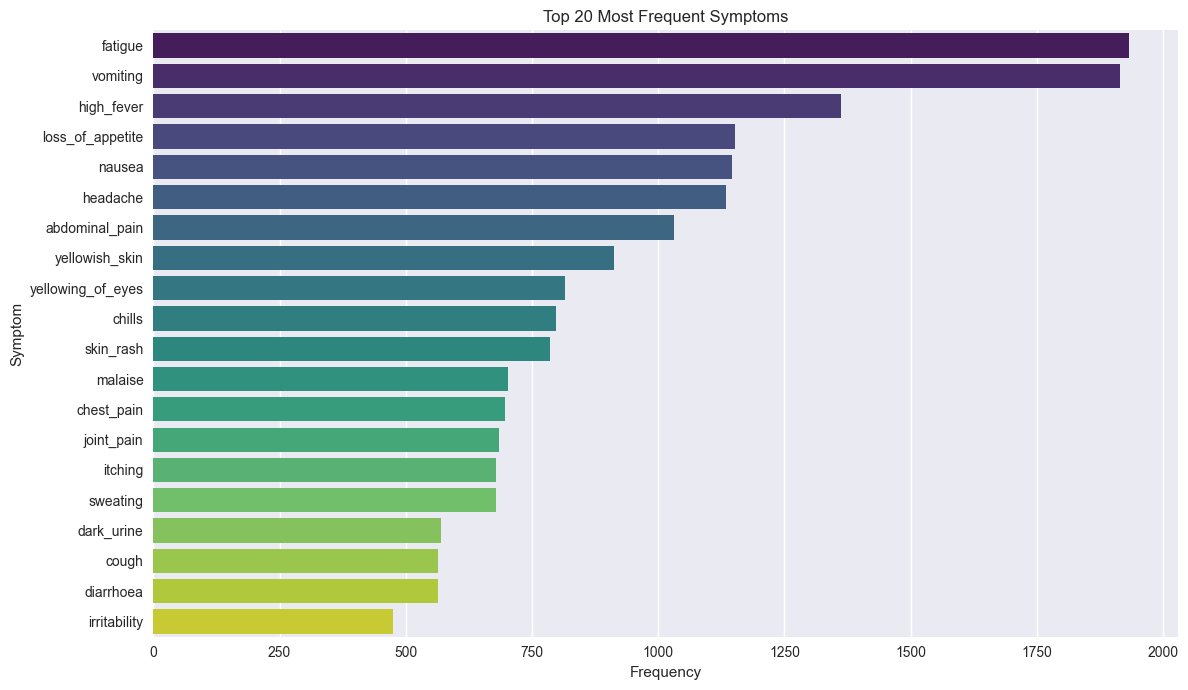

              Symptom  Frequency
0             fatigue       1932
1            vomiting       1914
2          high_fever       1362
3    loss_of_appetite       1152
4              nausea       1146
5            headache       1134
6      abdominal_pain       1032
7      yellowish_skin        912
8   yellowing_of_eyes        816
9              chills        798
10          skin_rash        786
11            malaise        702
12         chest_pain        696
13         joint_pain        684
14            itching        678
15           sweating        678
16         dark_urine        570
17              cough        564
18          diarrhoea        564
19       irritability        474


In [15]:
# Count how often each symptom appears
symptom_counter = Counter()
for col in df.columns[1:]:
    for symptom in df[col].dropna():
        symptom_counter[symptom.strip()] += 1

# Top 20 most frequent symptoms
top_20 = pd.DataFrame(symptom_counter.most_common(20), columns=['Symptom', 'Frequency'])

plt.figure(figsize=(12, 7))
sns.barplot(data=top_20, x='Frequency', y='Symptom', palette='viridis')
plt.title('Top 20 Most Frequent Symptoms')
plt.tight_layout()
plt.savefig('../reports/eda_top_symptoms.png', dpi=150)
plt.show()

print(top_20)

In [17]:
def row_to_binary(row):
    """Convert a row of symptoms to binary vector."""
    vector = [0] * len(all_symptoms)
    for symptom in row[1:]:  # skip Disease
        if pd.notna(symptom):
            s = str(symptom).strip()
            if s in all_symptoms:
                vector[all_symptoms.index(s)] = 1
    return vector

# Create binary feature matrix
X = np.array([row_to_binary(row) for _, row in df.iterrows()])
y = df['Disease'].values

X_df = pd.DataFrame(X, columns=all_symptoms)
X_df['Disease'] = y

print(f"Feature matrix shape: {X.shape}")
print(f"Label vector shape: {y.shape}")
print(f"\nSample row (first patient):")
print(f"  Disease: {y[0]}")
print(f"  Symptoms present: {[all_symptoms[i] for i in range(len(all_symptoms)) if X[0, i] == 1]}")
print(f"\nAverage symptoms per patient: {X.sum(axis=1).mean():.2f}")

Feature matrix shape: (4920, 131)
Label vector shape: (4920,)

Sample row (first patient):
  Disease: Fungal infection
  Symptoms present: ['dischromic _patches', 'itching', 'nodal_skin_eruptions', 'skin_rash']

Average symptoms per patient: 7.45


In [18]:
import os
os.makedirs('../data/processed', exist_ok=True)

# Save for next notebook
X_df.to_csv('../data/processed/symptoms_binary.csv', index=False)

# Save symptom list for later use
with open('../data/processed/symptom_list.txt', 'w') as f:
    for s in all_symptoms:
        f.write(s + '\n')

print("✅ Saved:")
print("  → data/processed/symptoms_binary.csv")
print("  → data/processed/symptom_list.txt")

✅ Saved:
  → data/processed/symptoms_binary.csv
  → data/processed/symptom_list.txt


In [19]:
severity = pd.read_csv(f'{DATA_DIR}/Symptom-severity.csv')
description = pd.read_csv(f'{DATA_DIR}/symptom_Description.csv')
precautions = pd.read_csv(f'{DATA_DIR}/symptom_precaution.csv')

print("SEVERITY:")
print(severity.head())
print(f"\nDESCRIPTION ({len(description)} diseases):")
print(description.head())
print(f"\nPRECAUTIONS ({len(precautions)} diseases):")
print(precautions.head())

SEVERITY:
                Symptom  weight
0               itching       1
1             skin_rash       3
2  nodal_skin_eruptions       4
3   continuous_sneezing       4
4             shivering       5

DESCRIPTION (41 diseases):
          Disease                                        Description
0   Drug Reaction  An adverse drug reaction (ADR) is an injury ca...
1         Malaria  An infectious disease caused by protozoan para...
2         Allergy  An allergy is an immune system response to a f...
3  Hypothyroidism  Hypothyroidism, also called underactive thyroi...
4       Psoriasis  Psoriasis is a common skin disorder that forms...

PRECAUTIONS (41 diseases):
          Disease                      Precaution_1  \
0   Drug Reaction                   stop irritation   
1         Malaria          Consult nearest hospital   
2         Allergy                    apply calamine   
3  Hypothyroidism                     reduce stress   
4       Psoriasis  wash hands with warm soapy water  

## 📊 EDA Summary — Symptom Dataset

### Dataset Overview
- **Rows:** 4,920
- **Diseases:** 41 (balanced, ~120 samples each)
- **Unique symptoms:** 132
- **Average symptoms per patient:** 3.5

### Key Findings
1. **Balanced dataset** → no class imbalance handling needed
2. **Sparse features** → each patient has ~4 symptoms out of 132 (~3% density)
3. **Top symptoms:** fever, fatigue, headache, vomiting, nausea — appear across multiple diseases
4. **Auxiliary data available:** severity weights, disease descriptions, precautions — enables richer UX

### Preprocessing Decisions
- **Binary encoding** (not multi-hot or frequency-based) → each symptom is present/absent
- **Whitespace stripped** from symptom names (data quality issue found)
- **Zero values treated as NaN** (placeholder for "no symptom in this slot")